# Obesity Level Prediction
Dataset: Obesity Levels by kaggle  
Model: Random Forest Classifier

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries ready")

Libraries ready


In [3]:
df = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

df.head()

Rows    : 2111
Columns : 17


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


##  Check the Data

In [4]:
print(df.info())
print()
print("Missing values:")
print(df.isnull().sum())
print()
print("Obesity level counts:")
print(df['NObeyesdad'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   object 
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   object 
 12  FAF                             21

##  Charts (Distribution + Gender)

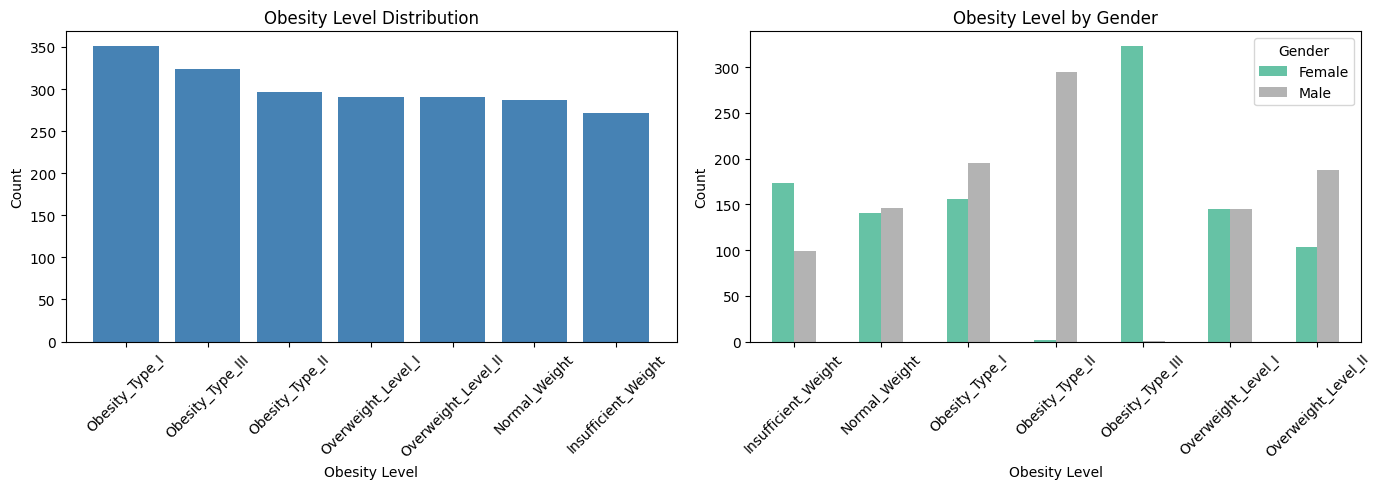

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# How many people in each obesity level
class_counts = df['NObeyesdad'].value_counts()
axes[0].bar(class_counts.index, class_counts.values, color='steelblue')
axes[0].set_title('Obesity Level Distribution')
axes[0].set_xlabel('Obesity Level')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Obesity level split by gender
gender_obesity = df.groupby(['Gender', 'NObeyesdad']).size().unstack(fill_value=0)
gender_obesity.T.plot(kind='bar', ax=axes[1], colormap='Set2')
axes[1].set_title('Obesity Level by Gender')
axes[1].set_xlabel('Obesity Level')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Gender')

plt.tight_layout()
plt.show()

##  Charts (Scatter + Boxplot)

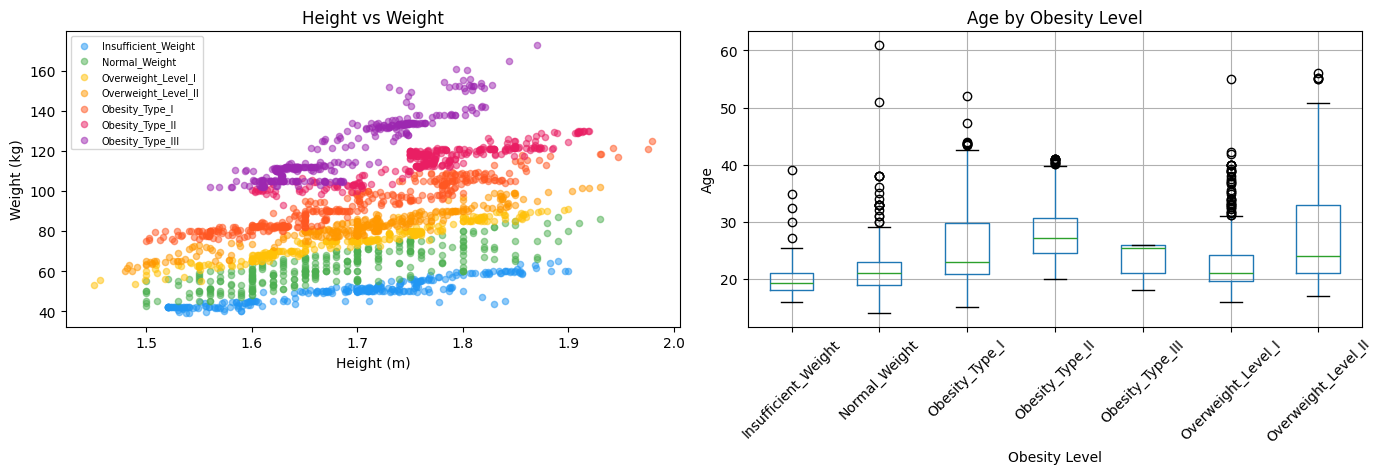

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Weight vs Height colored by obesity level
colors = {
    'Insufficient_Weight': '#2196F3',
    'Normal_Weight':        '#4CAF50',
    'Overweight_Level_I':   '#FFC107',
    'Overweight_Level_II':  '#FF9800',
    'Obesity_Type_I':       '#FF5722',
    'Obesity_Type_II':      '#E91E63',
    'Obesity_Type_III':     '#9C27B0'
}
for label, color in colors.items():
    subset = df[df['NObeyesdad'] == label]
    axes[0].scatter(subset['Height'], subset['Weight'], c=color, label=label, alpha=0.5, s=20)
axes[0].set_title('Height vs Weight')
axes[0].set_xlabel('Height (m)')
axes[0].set_ylabel('Weight (kg)')
axes[0].legend(fontsize=7)

# Age range for each obesity level
df.boxplot(column='Age', by='NObeyesdad', ax=axes[1])
axes[1].set_title('Age by Obesity Level')
axes[1].set_xlabel('Obesity Level')
axes[1].set_ylabel('Age')
plt.xticks(rotation=45)
plt.suptitle('')

plt.tight_layout()
plt.show()

##  Encode Categorical Columns

In [7]:
df_processed = df.copy()

categorical_columns = ['Gender', 'CALC', 'FAVC', 'SCC', 'SMOKE',
                        'family_history_with_overweight', 'CAEC', 'MTRANS']

label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    df_processed[col] = le.fit_transform(df_processed[col])
    label_encoders[col] = le

target_encoder = LabelEncoder()
df_processed['NObeyesdad'] = target_encoder.fit_transform(df_processed['NObeyesdad'])

print("Encoding done")
print("Target classes:", list(target_encoder.classes_))

Encoding done
Target classes: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


## Split Data

In [8]:
X = df_processed.drop('NObeyesdad', axis=1)
y = df_processed['NObeyesdad']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])

Training samples : 1688
Testing samples  : 423


##  Train Model

In [9]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Model training complete")

Model training complete


## Evaluate Model

In [10]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")
print()
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_))

Accuracy: 95.04 %

                     precision    recall  f1-score   support

Insufficient_Weight       1.00      0.96      0.98        56
      Normal_Weight       0.87      0.94      0.90        62
     Obesity_Type_I       0.99      0.95      0.97        78
    Obesity_Type_II       0.97      0.98      0.97        58
   Obesity_Type_III       1.00      1.00      1.00        63
 Overweight_Level_I       0.87      0.86      0.86        56
Overweight_Level_II       0.96      0.96      0.96        50

           accuracy                           0.95       423
          macro avg       0.95      0.95      0.95       423
       weighted avg       0.95      0.95      0.95       423



##  Confusion Matrix + Feature Importance

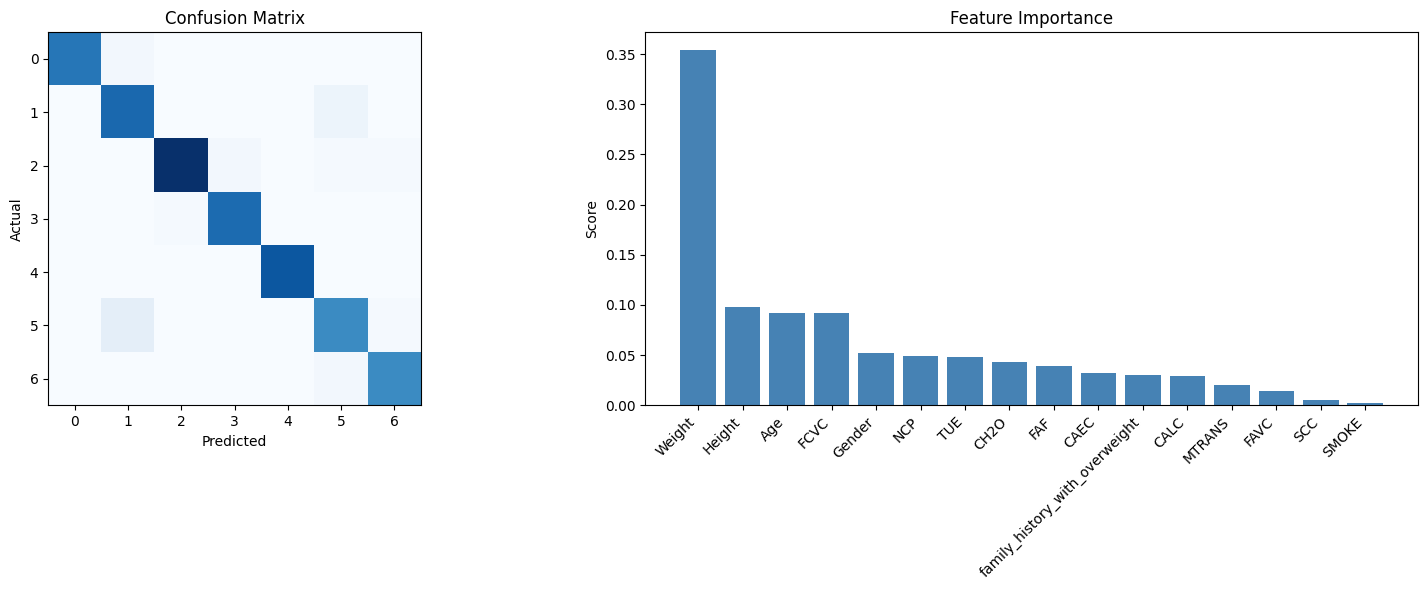

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Feature importance
feature_names = X.columns.tolist()
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
axes[1].bar(range(len(feature_names)), importances[indices], color='steelblue')
axes[1].set_xticks(range(len(feature_names)))
axes[1].set_xticklabels([feature_names[i] for i in indices], rotation=45, ha='right')
axes[1].set_title('Feature Importance')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

## Save Model

In [12]:
joblib.dump(model,          'obesity_model.pkl')
joblib.dump(scaler,         'scaler.pkl')
joblib.dump(label_encoders, 'label_encoders.pkl')
joblib.dump(target_encoder, 'target_encoder.pkl')

feature_info = {
    'feature_names':       X.columns.tolist(),
    'categorical_columns': categorical_columns,
    'target_classes':      list(target_encoder.classes_)
}
joblib.dump(feature_info, 'feature_info.pkl')

print("All model files saved")

All model files saved


##  Download Model Files

In [13]:
from google.colab import files

files.download('obesity_model.pkl')
files.download('scaler.pkl')
files.download('label_encoders.pkl')
files.download('target_encoder.pkl')
files.download('feature_info.pkl')

print("Download complete")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download complete


##  Test One Prediction

In [18]:
sample = pd.DataFrame([{
    'Age': 25, 'Gender': 'Male', 'Height': 1.75, 'Weight': 85,
    'CALC': 'Sometimes', 'FAVC': 'yes', 'FCVC': 2, 'NCP': 3,
    'SCC': 'no', 'SMOKE': 'no', 'CH2O': 2,
    'family_history_with_overweight': 'yes',
    'FAF': 1, 'TUE': 2, 'CAEC': 'Sometimes', 'MTRANS': 'Public_Transportation'
}])

for col in categorical_columns:
    sample[col] = label_encoders[col].transform(sample[col])

sample_scaled = scaler.transform(sample)
prediction = model.predict(sample_scaled)
result = target_encoder.inverse_transform(prediction)[0]

print("Predicted Obesity Level:", result)

Predicted Obesity Level: Overweight_Level_II
